# Customer Segmentation & Revenue Forecasting

**Goal:** find which customers are most valuable and which are slipping away, and test how well daily revenue can be forecast.

**Data:** two years of sales from a UK online gift-ware retailer (December 2009 to December 2011): 1,067,371 raw transactions, cleaned down to 804,824 rows and 5,855 customers.

**This notebook has five parts:**

- **Part 1: Explore the raw data.** Look for problems and decide how to handle each one.

- **Part 2: Cleaning.** Apply those decisions.

- **Part 3: RFM feature engineering.** For each customer: Recency (days since last purchase), Frequency (number of orders) and Monetary (total spend).

- **Part 4: Clustering.** Group customers into five segments with K-means and name them.

- **Part 5: Revenue forecasting.** Compare Prophet, XGBoost and Random Forest against a simple guess.

**Main results:**

- **8.0% of customers (Champions) bring in 55.0% of revenue.**

- **The chosen forecast is off by about 31% on a typical day.** A simple guess is off by about 41%.

---

# Part 1: Explore the Raw Data

In [1]:
import pandas as pd


In [2]:
data = pd.read_csv("online_retail_II.csv", encoding="ISO-8859-1")
print(data.shape)
print(data.dtypes)
print(data.head())

(1067371, 8)
Invoice         object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
Price          float64
Customer ID    float64
Country         object
dtype: object
  Invoice StockCode                          Description  Quantity  \
0  489434     85048  15CM CHRISTMAS GLASS BALL 20 LIGHTS        12   
1  489434    79323P                   PINK CHERRY LIGHTS        12   
2  489434    79323W                  WHITE CHERRY LIGHTS        12   
3  489434     22041         RECORD FRAME 7" SINGLE SIZE         48   
4  489434     21232       STRAWBERRY CERAMIC TRINKET BOX        24   

           InvoiceDate  Price  Customer ID         Country  
0  2009-12-01 07:45:00   6.95      13085.0  United Kingdom  
1  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
2  2009-12-01 07:45:00   6.75      13085.0  United Kingdom  
3  2009-12-01 07:45:00   2.10      13085.0  United Kingdom  
4  2009-12-01 07:45:00   1.25      13085.0  United Kingdom  


In [3]:
print(data["Description"].str.contains("Ã|Â|�", na=False, regex=True).sum())


79


## Missing Values

In [4]:
print(data.isnull().sum())
print(data.isnull().mean() * 100)

Invoice             0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
Price               0
Customer ID    243007
Country             0
dtype: int64
Invoice         0.000000
StockCode       0.000000
Description     0.410541
Quantity        0.000000
InvoiceDate     0.000000
Price           0.000000
Customer ID    22.766873
Country         0.000000
dtype: float64


## Date Range Check

In [5]:
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])
print(data["InvoiceDate"].min(), data["InvoiceDate"].max())

2009-12-01 07:45:00 2011-12-09 12:50:00


### Why Recency Needs a Fixed Reference Date

Recency is "how many days since this customer's last purchase." That's a relative measurement — it needs a fixed point to count backward from. The natural choice is the max date in the dataset (2011-12-09), or one day after it, used as a stand-in for "today" within the context of this dataset.

If you instead used today's real-world date (2026), every single customer's Recency would be enormous — the "most recent" customer, who bought something on 2011-12-09, would show a Recency of roughly 5,300+ days. That number would be technically correct but completely useless for segmentation, because every customer would look equally "long gone," and you'd lose all ability to distinguish an actively engaged customer from a truly inactive one — the entire point of Recency as a signal would collapse.

So the rule is: Recency's reference point should be relative to the dataset's own timeframe, not the real-world calendar, unless you're specifically building something that updates live against real time (which this static, historical dataset isn't).

## Uniqueness Counts

In [6]:
print("unique customers:", data["Customer ID"].nunique())
print("unique invoices:", data["Invoice"].nunique())
print("unique products (stockcode):", data["StockCode"].nunique())
print("unique countries:", data["Country"].nunique())
print(data["Country"].value_counts().head(10))

unique customers: 5942
unique invoices: 53628
unique products (stockcode): 5305
unique countries: 43
Country
United Kingdom    981330
EIRE               17866
Germany            17624
France             14330
Netherlands         5140
Spain               3811
Switzerland         3189
Belgium             3123
Portugal            2620
Australia           1913
Name: count, dtype: int64


### Decision: Keep All Countries

92% of the data is from the UK, and the remaining 8% is spread thinly across 42 other countries.

I'd keep all rows and all real country labels (not collapse non-UK countries into a generic "Other" bucket), and run a single RFM + clustering model across the full customer base — since Country isn't actually used in the RFM calculation itself (Recency/Frequency/Monetary don't depend on it), it doesn't need to affect how the model is built. I would not build separate models per country, since most non-UK countries have too few customers (some in the single digits) to cluster meaningfully on their own. After clustering, I'd report Country as a secondary breakdown — e.g., what % of each segment is UK vs. other countries — and note in the write-up that ~92% of the data is UK-based, so results should be understood as primarily reflecting UK customer behavior.

## Quantity Distribution & Anomalies

In [7]:
print(data["Quantity"].describe())
print("Negative quantity rows:", (data["Quantity"] < 0).sum())
print("Zero quantity rows:", (data["Quantity"] == 0).sum())


count    1.067371e+06
mean     9.938898e+00
std      1.727058e+02
min     -8.099500e+04
25%      1.000000e+00
50%      3.000000e+00
75%      1.000000e+01
max      8.099500e+04
Name: Quantity, dtype: float64
Negative quantity rows: 22950
Zero quantity rows: 0


### Why the Median Describes a Typical Order Better Than the Mean

The gap between mean and median signals a right-skewed distribution — a small number of extreme outliers (like the 80,995-unit bulk order we found) are pulling the mean upward, even though most transactions are actually small (the median of 3 reflects what a typical order really looks like). This happens because mean is calculated by summing every value and dividing by count, so every value — including extreme outliers — pulls on it equally. Median only depends on position (the middle value when sorted), not magnitude, so it's resistant to outliers. In this dataset, using mean Quantity to describe a "typical customer" would be misleading, since it's distorted by a handful of wholesale-scale orders that don't represent most customers' actual behavior.

## Price Distribution & Anomalies

In [8]:
print(data["Price"].describe())
print("Negative price rows:", (data["Price"] < 0).sum())
print("Zero price rows:", (data["Price"] == 0).sum())


count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: Price, dtype: float64
Negative price rows: 5
Zero price rows: 6202


### Decision: Zero-Price Rows

Yes — you can't apply one blanket rule to all zero-price rows, because they're not a single category. Looking at a sample, most zero-price rows fall into two groups: internal warehouse/inventory noise (descriptions like "short," "lost," "damages," "mixed," or unclear codes), and legitimate charge types like DOTCOM POSTAGE priced at £0 in a specific row. Almost all of these also have a missing Customer ID, meaning they'd already be removed by the first cleaning step regardless. The exception is rows with a real product description AND a real Customer ID (e.g., "6 RIBBONS EMPIRE" with Customer ID 16126.0) — these survive the missing-ID filter and need their own explicit decision. Before dropping any zero-price rows, I'd filter specifically to Price == 0 AND Customer ID not null, to see how many rows actually remain after the first cleaning step, rather than assuming the full 6,202 count still applies. Since Monetary is based on real revenue, a £0 transaction contributes nothing to it either way, so dropping the remaining ones is still reasonable — but the count needs to be verified, not assumed.

## Cancelled Invoices

In [9]:
cancelled = data["Invoice"].astype(str).str.startswith("C")
print("Cancelled invoice rows:", cancelled.sum())
print(cancelled.mean() * 100, "% of rows")

Cancelled invoice rows: 19494
1.8263565339511754 % of rows


### Three Different Anomaly Patterns

The data has three different negative-quantity patterns: (1) cancelled invoices, where the Invoice starts with "C"; (2) internal warehouse adjustments, with negative quantity, a zero price and no Customer ID; and (3) "Adjust bad debt" rows, with StockCode "B", a negative price and no Customer ID.

Filtering only on the "C" prefix would correctly catch the 19,494 customer-initiated cancellations, but it would miss the ~3,457 internal warehouse-adjustment rows and the 5 "Adjust bad debt" rows, since neither of those patterns is reflected in the invoice number — they'd slide straight through into the "cleaned" dataset undetected. In this specific dataset, it turns out not to matter much in practice, because nearly all of those rows also have a missing Customer ID, so they get removed anyway by the very first cleaning step (dropping missing Customer ID) before the cancellation filter even runs. But that's a coincidence of this particular dataset, not something to rely on generally — if even one adjustment row had a real Customer ID attached, a C-prefix-only filter would silently let bad data corrupt that customer's RFM numbers with no warning. The lesson is not to assume one filter catches everything just because it handles the obvious case — each anomaly pattern needs to be checked independently and verified against what's already being removed, rather than assumed to be covered.

## Duplicates

In [10]:
dupes = data[data.duplicated(keep=False)]
print(dupes.sort_values("Invoice").head(20))


    Invoice StockCode                        Description  Quantity  \
362  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   
394  489517     21912           VINTAGE SNAKES & LADDERS         1   
391  489517     21491    SET OF THREE VINTAGE GIFT WRAPS         1   
390  489517    84951A    S/4 PISTACHIO LOVEBIRD COASTERS         1   
388  489517    84951A    S/4 PISTACHIO LOVEBIRD COASTERS         1   
386  489517     21821   GLITTER STAR GARLAND WITH BELLS          1   
385  489517     21913     VINTAGE SEASIDE JIGSAW PUZZLES         1   
384  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
379  489517     21491    SET OF THREE VINTAGE GIFT WRAPS         1   
371  489517     21912           VINTAGE SNAKES & LADDERS         1   
368  489517     22130   PARTY CONE CHRISTMAS DECORATION          6   
367  489517     22319  HAIRCLIPS FORTIES FABRIC ASSORTED        12   
365  489517     21821   GLITTER STAR GARLAND WITH BELLS          1   
363  489517     2191

### Decision: Keep the Repeated Rows

Yes, it matters a lot — and the initial assumption that "exact duplicates should be dropped" turned out to be wrong for this dataset. If duplicates were a true data export glitch, you'd expect the entire invoice to be logged twice, in the same relative order. Instead, individual line items within the same invoice (same Invoice number, same customer, same timestamp) repeat inconsistently — some products appear once, others two or three times. This pattern is more consistent with a customer genuinely adding the same product to their cart multiple times as separate entries, or the system splitting a quantity into multiple rows, rather than an export error. Since these rows represent real purchased units and real revenue, running .drop_duplicates() would silently delete legitimate quantity and undercount that customer's true Frequency and Monetary values. Decision: keep these rows and do not run .drop_duplicates() on the dataset, documenting the investigation and reasoning rather than applying a blanket rule based on an untested assumption.

## Non-Product Stock Codes

In [11]:
non_numeric = data[~data["StockCode"].astype(str).str.match(r"^\d")]
print(non_numeric["StockCode"].value_counts().head(20))


StockCode
POST            2122
DOT             1446
M               1421
C2               282
D                177
S                104
BANK CHARGES     102
ADJUST            67
AMAZONFEE         43
DCGS0058          31
gift_0001_20      29
gift_0001_30      29
DCGSSGIRL         25
DCGSSBOY          23
PADS              19
gift_0001_10      16
CRUK              16
TEST001           15
DCGS0076          15
DCGS0003          14
Name: count, dtype: int64


### Decision: Stock Codes Need More Than One Rule

One blanket rule would be a mistake here — the non-numeric codes aren't a single category, they represent at least three different things: legitimate customer-paid revenue (POST, DOT, C2 for postage/carriage; gift_0001_xx for gift cards), pure accounting/administrative noise that should be dropped (M, D, BANK CHARGES, ADJUST, AMAZONFEE, TEST001, CRUK), and ambiguous cases that need direct investigation before deciding (S for samples — likely £0 price and not a real paid transaction; the DCGS-prefixed codes, which don't match the standard numeric pattern but may still be real products with non-standard SKUs). If I dropped everything non-numeric with one rule, I'd incorrectly remove real revenue like postage charges, which would undercount customers' true Monetary values. The risk of a single blanket rule is treating "doesn't match my regex" as equivalent to "not a real transaction," when in reality the pattern only tells you a code is unusual, not why it's unusual — each type needs to be checked individually against its actual meaning before deciding whether it belongs in the cleaned dataset.

---

# Part 2: Cleaning

Apply the decisions above, one step at a time.

In [12]:
before = len(data)
data = data[data["Customer ID"].notnull()]
print(f"Dropped {before - len(data)} rows -> {len(data)} remaining")


Dropped 243007 rows -> 824364 remaining


In [13]:
before = len(data)
data = data[~data["Invoice"].astype(str).str.startswith("C")]
print(f"Dropped {before - len(data)} rows -> {len(data)} remaining")


Dropped 18744 rows -> 805620 remaining


In [14]:
before = len(data)
admin_codes = ["M", "D", "BANK CHARGES", "ADJUST", "AMAZONFEE", "TEST001", "CRUK"]
data = data[~data["StockCode"].isin(admin_codes)]
print(f"Dropped {before - len(data)} rows -> {len(data)} remaining")

Dropped 796 rows -> 804824 remaining


In [15]:
print(
    data[data["StockCode"] == "S"][
        ["StockCode", "Description", "Quantity", "Price"]
    ].head(10)
)


Empty DataFrame
Columns: [StockCode, Description, Quantity, Price]
Index: []


In [16]:
print(
    data[data["StockCode"].astype(str).str.startswith("DCGS")][
        ["StockCode", "Description"]
    ]
    .drop_duplicates()
    .head(10)
)


Empty DataFrame
Columns: [StockCode, Description]
Index: []


In [17]:
print(
    f"FINAL: {len(data)} rows | {data['Customer ID'].nunique()} customers | {data['Invoice'].nunique()} invoices"
)
data.to_csv("cleaned_retail.csv", index=False)


FINAL: 804824 rows | 5855 customers | 36718 invoices


---

# Part 3: RFM Feature Engineering

Recency, Frequency and Monetary are calculated two separate ways, in SQL and in pandas, to cross-check the result.

In [18]:
import duckdb

In [19]:
data = pd.read_csv("cleaned_retail.csv")
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

print(data.shape)


(804824, 8)


In [20]:
con = duckdb.connect()
con.register("retail", data)

con.sql("select * from retail limit 5").show()

┌─────────┬───────────┬─────────────────────────────────────┬──────────┬─────────────────────┬────────┬─────────────┬────────────────┐
│ Invoice │ StockCode │             Description             │ Quantity │     InvoiceDate     │ Price  │ Customer ID │    Country     │
│  int64  │  varchar  │               varchar               │  int64   │      timestamp      │ double │   double    │    varchar     │
├─────────┼───────────┼─────────────────────────────────────┼──────────┼─────────────────────┼────────┼─────────────┼────────────────┤
│  489434 │ 85048     │ 15CM CHRISTMAS GLASS BALL 20 LIGHTS │       12 │ 2009-12-01 07:45:00 │   6.95 │     13085.0 │ United Kingdom │
│  489434 │ 79323P    │ PINK CHERRY LIGHTS                  │       12 │ 2009-12-01 07:45:00 │   6.75 │     13085.0 │ United Kingdom │
│  489434 │ 79323W    │  WHITE CHERRY LIGHTS                │       12 │ 2009-12-01 07:45:00 │   6.75 │     13085.0 │ United Kingdom │
│  489434 │ 22041     │ RECORD FRAME 7" SINGLE SIZE    

In [21]:
con.sql("""
select "Customer ID",sum(Quantity * Price) as Monetary from retail
group by "Customer ID"
order by Monetary Desc
limit 10""").show()

┌─────────────┬────────────────────┐
│ Customer ID │      Monetary      │
│   double    │       double       │
├─────────────┼────────────────────┤
│     18102.0 │  608821.6499999999 │
│     14646.0 │  528602.5199999993 │
│     14156.0 │  305228.6299999994 │
│     14911.0 │          284029.61 │
│     17450.0 │          246973.09 │
│     13694.0 │ 196482.81000000006 │
│     17511.0 │  175603.5499999999 │
│     16446.0 │           168472.5 │
│     16684.0 │          147142.77 │
│     12415.0 │          144383.37 │
└─────────────┴────────────────────┘
  10 rows                2 columns



### Checking an Extreme Customer

Customer 18102 has a Monetary value of £608,821.65, far higher than most customers (many are in the hundreds of pounds). Before clustering, I checked whether this is a data error or a genuine wholesale buyer.

In [22]:
con.sql("""
SELECT
    Invoice,
    StockCode,
    Description,
    Quantity,
    Price,
    InvoiceDate
FROM retail
WHERE "Customer ID" = 18102
ORDER BY InvoiceDate
""").show()


┌─────────┬───────────┬─────────────────────────────────────┬──────────┬────────┬─────────────────────┐
│ Invoice │ StockCode │             Description             │ Quantity │ Price  │     InvoiceDate     │
│  int64  │  varchar  │               varchar               │  int64   │ double │      timestamp      │
├─────────┼───────────┼─────────────────────────────────────┼──────────┼────────┼─────────────────────┤
│  489438 │ 21329     │ DINOSAURS  WRITING SET              │       28 │   0.98 │ 2009-12-01 09:24:00 │
│  489438 │ 21252     │ SET OF MEADOW  FLOWER STICKERS      │       30 │   1.69 │ 2009-12-01 09:24:00 │
│  489438 │ 21100     │ CHARLIE AND LOLA CHARLOTTE BAG      │       30 │   1.15 │ 2009-12-01 09:24:00 │
│  489438 │ 21033     │ JUMBO BAG CHARLIE AND LOLA TOYS     │       30 │    2.0 │ 2009-12-01 09:24:00 │
│  489438 │ 20711     │ JUMBO BAG TOYS                      │       60 │    1.3 │ 2009-12-01 09:24:00 │
│  489438 │ 21410     │ COUNTRY COTTAGE  DOORSTOP GREEN     │   

First check: how many separate invoices, and over what time span?

In [23]:
con.sql("""
select
count(Distinct Invoice) as num_invoices,
MIN(InvoiceDate) as first_purchase,
MAX(InvoiceDate) as last_purchase,
COUNT(*) AS num_line_items
from retail
where "Customer Id" = 18102
""").show()

┌──────────────┬─────────────────────┬─────────────────────┬────────────────┐
│ num_invoices │   first_purchase    │    last_purchase    │ num_line_items │
│    int64     │      timestamp      │      timestamp      │     int64      │
├──────────────┼─────────────────────┼─────────────────────┼────────────────┤
│          145 │ 2009-12-01 09:24:00 │ 2011-12-09 11:50:00 │           1058 │
└──────────────┴─────────────────────┴─────────────────────┴────────────────┘



Second check: which country, and is the product mix consistent (the same few items bought repeatedly, which is common for a business reselling stock)?

In [24]:
con.sql("""
select
Country,StockCode,Description,Sum(Quantity) as total_qty
from retail
where "Customer ID" = 18102
group by Country,StockCode,Description
order by total_qty Desc
Limit 10
""").show()

┌────────────────┬───────────┬───────────────────────────────────┬───────────┐
│    Country     │ StockCode │            Description            │ total_qty │
│    varchar     │  varchar  │              varchar              │  int128   │
├────────────────┼───────────┼───────────────────────────────────┼───────────┤
│ United Kingdom │ 22189     │ CREAM HEART CARD HOLDER           │     11324 │
│ United Kingdom │ 22188     │ BLACK HEART CARD HOLDER           │      9938 │
│ United Kingdom │ 82484     │ WOOD BLACK BOARD ANT WHITE FINISH │      6001 │
│ United Kingdom │ 21623     │ VINTAGE UNION JACK MEMOBOARD      │      5168 │
│ United Kingdom │ 21877     │ HOME SWEET HOME MUG               │      3712 │
│ United Kingdom │ 21872     │ GLAMOROUS  MUG                    │      2902 │
│ United Kingdom │ 48194     │ DOORMAT HEARTS                    │      2460 │
│ United Kingdom │ 22507     │ MEMO BOARD RETROSPOT  DESIGN      │      2360 │
│ United Kingdom │ 21871     │ SAVE THE PLANET MUG  

**Result:** For Customer 18102, I found 145 distinct invoices spanning almost the full 2-year dataset, with consistent repeated bulk purchases of home-décor items (thousands of units of the same products) — this rules out a one-time data error and strongly suggests a wholesale/reseller account rather than an individual consumer. This matters for clustering because the project's core question is about individual customer loyalty and retention, and wholesale purchasing patterns reflect business restocking cycles, not consumer engagement — mixing them into the same K-means model would either isolate wholesale accounts into a meaningless single-customer cluster or distort distance calculations for everyone else, since K-means is sensitive to scale. My first plan was to separate wholesale-scale accounts with a threshold. I revisited this in the clustering section and let the clustering find them instead.

In [25]:
con.sql("""
SELECT
    "Customer ID",
    SUM(Quantity * Price) AS Monetary
FROM retail
GROUP BY "Customer ID"
""").df()["Monetary"].describe()


count      5855.000000
mean       3003.665619
std       14670.476488
min           0.000000
25%         349.025000
50%         898.960000
75%        2303.130000
max      608821.650000
Name: Monetary, dtype: float64

### Note for Clustering: Monetary Is Heavily Skewed

Monetary is heavily right-skewed (mean £3,003 vs. median £899, max £608,821), so it needs transforming before K-means.

Transform — because K-means uses distance-based math, and an unscaled feature with this much range (e.g., £0 to £608,821) would dominate the clustering, making Recency and Frequency almost irrelevant by comparison. A log transform (e.g., log(Monetary + 1)) compresses the extreme range while preserving meaningful differences among typical customers, preventing wholesale-scale outliers from distorting the whole model.

In [26]:
con.sql("""
select
"Customer ID",
count(distinct Invoice) as Frequency
from retail
group by "Customer ID"
ORDER BY FREQUENCY DESC
LIMIT 10
""").show()

┌─────────────┬───────────┐
│ Customer ID │ Frequency │
│   double    │   int64   │
├─────────────┼───────────┤
│     14911.0 │       375 │
│     12748.0 │       324 │
│     17841.0 │       211 │
│     15311.0 │       207 │
│     13089.0 │       203 │
│     14606.0 │       185 │
│     17850.0 │       155 │
│     14646.0 │       152 │
│     18102.0 │       145 │
│     14156.0 │       145 │
└─────────────┴───────────┘
  10 rows       2 columns



In [27]:
con.sql("""
SELECT
    "Customer ID",
    COUNT(DISTINCT Invoice) AS Frequency
FROM retail
GROUP BY "Customer ID"
""").df()["Frequency"].describe()


count    5855.000000
mean        6.271221
std        12.799145
min         1.000000
25%         1.000000
50%         3.000000
75%         7.000000
max       375.000000
Name: Frequency, dtype: float64

In [28]:
con.sql("SELECT MAX(InvoiceDate) AS max_date FROM retail").show()


┌─────────────────────┐
│      max_date       │
│      timestamp      │
├─────────────────────┤
│ 2011-12-09 12:50:00 │
└─────────────────────┘



In [29]:
con.sql("""
select
"Customer ID",
date_diff('day',max(InvoiceDate),(select max(InvoiceDate) from retail)) as Recency
from retail
group by "Customer ID"
order by Recency desc
limit 10
""").show()

┌─────────────┬─────────┐
│ Customer ID │ Recency │
│   double    │  int64  │
├─────────────┼─────────┤
│     14654.0 │     738 │
│     13526.0 │     738 │
│     17056.0 │     738 │
│     12636.0 │     738 │
│     17592.0 │     738 │
│     17909.0 │     737 │
│     17087.0 │     737 │
│     14980.0 │     737 │
│     17606.0 │     737 │
│     17818.0 │     737 │
└─────────────┴─────────┘
  10 rows     2 columns



In [30]:
con.sql("""
SELECT
    "Customer ID",
    DATE_DIFF('day', MAX(InvoiceDate), (SELECT MAX(InvoiceDate) FROM retail)) AS Recency
FROM retail
GROUP BY "Customer ID"
""").df()["Recency"].describe()


count    5855.000000
mean      199.794876
std       208.610894
min         0.000000
25%        25.000000
50%        95.000000
75%       379.000000
max       738.000000
Name: Recency, dtype: float64

In [31]:
rfm = con.sql("""
select
"Customer ID",
DATE_DIFF('day', MAX(InvoiceDate), (SELECT MAX(InvoiceDate) FROM retail)) AS Recency,
    COUNT(DISTINCT Invoice) AS Frequency,
    SUM(Quantity * Price) AS Monetary
FROM retail
GROUP BY "Customer ID"
ORDER BY "Customer ID"
""").df()

print(rfm.shape)
print(rfm.head())

(5855, 4)
   Customer ID  Recency  Frequency  Monetary
0      12346.0      325          4  77353.96
1      12347.0        2          8   5633.32
2      12348.0       75          5   2019.40
3      12349.0       18          4   4428.69
4      12350.0      310          1    334.40


In [32]:
print(rfm.isnull().sum())
print(rfm.describe())


Customer ID    0
Recency        0
Frequency      0
Monetary       0
dtype: int64
        Customer ID      Recency    Frequency       Monetary
count   5855.000000  5855.000000  5855.000000    5855.000000
mean   15318.455167   199.794876     6.271221    3003.665619
std     1715.393034   208.610894    12.799145   14670.476488
min    12346.000000     0.000000     1.000000       0.000000
25%    13835.500000    25.000000     1.000000     349.025000
50%    15319.000000    95.000000     3.000000     898.960000
75%    16801.500000   379.000000     7.000000    2303.130000
max    18287.000000   738.000000   375.000000  608821.650000


In [33]:
# Monetary
data["Revenue"] = data["Quantity"] * data["Price"]
monetary_pd = data.groupby("Customer ID")["Revenue"].sum()

# Frequency
frequency_pd = data.groupby("Customer ID")["Invoice"].nunique()

# Recency
max_date = data["InvoiceDate"].max()
last_purchase = data.groupby("Customer ID")["InvoiceDate"].max()
recency_pd = (max_date - last_purchase).dt.days

# Combine into one DataFrame
rfm_pandas = pd.DataFrame(
    {"Recency": recency_pd, "Frequency": frequency_pd, "Monetary": monetary_pd}
).reset_index()

print(rfm_pandas.shape)
print(rfm_pandas.head())


(5855, 4)
   Customer ID  Recency  Frequency  Monetary
0      12346.0      325          4  77353.96
1      12347.0        1          8   5633.32
2      12348.0       74          5   2019.40
3      12349.0       18          4   4428.69
4      12350.0      309          1    334.40


In [34]:
comparison = rfm.merge(rfm_pandas, on="Customer ID", suffixes=("_sql", "_pandas"))

comparison["Recency_diff"] = comparison["Recency_sql"] - comparison["Recency_pandas"]
comparison["Frequency_diff"] = (
    comparison["Frequency_sql"] - comparison["Frequency_pandas"]
)
comparison["Monetary_diff"] = comparison["Monetary_sql"] - comparison["Monetary_pandas"]

print(comparison[["Recency_diff", "Frequency_diff", "Monetary_diff"]].describe())


       Recency_diff  Frequency_diff  Monetary_diff
count   5855.000000          5855.0   5.855000e+03
mean       0.533903             0.0  -4.605694e-14
std        0.498892             0.0   1.217404e-11
min        0.000000             0.0  -5.238689e-10
25%        0.000000             0.0  -5.684342e-14
50%        1.000000             0.0   0.000000e+00
75%        1.000000             0.0   4.263256e-14
max        1.000000             0.0   4.220055e-10


## RFM Feature Engineering: Summary

### What was built
Computed Recency, Frequency, and Monetary per customer, two independent ways:
1. SQL (via duckdb, run directly against the cleaned dataset)
2. Pandas (groupby-based), as a cross-check

### Final RFM table
- 5,855 rows (one per customer), 4 columns: Customer ID, Recency, Frequency, Monetary
- Zero missing values across all columns

### Key distributions (all 5,855 customers)
| Metric | Mean | Median | Max | Notes |
|---|---|---|---|---|
| Recency (days) | 199.8 | 95 | 738 | Less skewed than F/M; bounded by dataset's 2-year span |
| Frequency (# invoices) | 6.27 | 3 | 375 | Heavily right-skewed; 25% of customers ordered only once |
| Monetary (£) | 3,003.67 | 898.96 | 608,821.65 | Heavily right-skewed; driven by a small number of wholesale-scale accounts |

### Key finding: wholesale/B2B accounts exist in the data
Investigated the top Monetary/Frequency outliers (Customer 18102 and 14156) directly:
- 145+ distinct invoices each, spanning nearly the full 2-year dataset
- Consistent, repeated bulk purchases of the same product categories (thousands of units)
- Conclusion: these are very likely wholesale/reseller accounts, not individual consumers
- First plan: since the project's core question is about individual customer retention, wholesale-scale accounts should be identified via a defensible threshold and treated as a separate category rather than clustered together with retail customers

### Validation: SQL vs. pandas cross-check
- Frequency: exact match across all 5,855 customers (0 difference)
- Monetary: matched to within floating-point rounding error (~1e-10, not a real discrepancy)
- Recency: systematic 0-or-1-day difference across roughly half of customers — explained in the next section

### Decisions carried into clustering
- Log-transform Recency, Frequency, and Monetary before clustering, since all are right-skewed and K-means is distance-based (an untransformed Monetary of £608K would dominate the model)
- Decide how to handle wholesale-scale accounts before or during clustering

In [35]:
# Pick one customer where SQL and pandas disagreed, and look at the actual timestamps
sample_customer = comparison[comparison["Recency_diff"] == 1]["Customer ID"].iloc[0]
print("Customer ID:", sample_customer)
print(
    "Their last purchase timestamp:",
    data[data["Customer ID"] == sample_customer]["InvoiceDate"].max(),
)
print("Dataset max timestamp:", data["InvoiceDate"].max())


Customer ID: 12347.0


Their last purchase timestamp: 2011-12-07 15:52:00
Dataset max timestamp: 2011-12-09 12:50:00


### Why SQL and pandas Disagreed on Recency

The Recency values from SQL and pandas differed by exactly 0 or 1 day for roughly half of customers, never a fraction and never anything else.

SQL's DATE_DIFF('day', ...) compares only the calendar-date portion of two timestamps, ignoring time-of-day entirely — so Nov 18 to Dec 9 is calculated as a flat 21 days regardless of the specific times involved. Pandas' .dt.days (from subtracting two full timestamps) calculates the exact elapsed time in hours, then floors to whole days — so the same Nov 18 4:19pm to Dec 9 12:50pm gap comes out as 20 days, since the partial final day hadn't fully elapsed yet by clock time. Neither approach is incorrect, but they represent two different definitions of "days since last purchase." Decision: use SQL's calendar-date version as final, since RFM segmentation operates at day-level business granularity, not hour-level precision — two customers who both purchased "on November 18th" shouldn't get different Recency values just because one checked out in the morning and the other at night. This also matches the common convention used in most RFM implementations.

In [36]:
rfm.to_csv("rfm_table.csv", index=False)
print("Saved:", rfm.shape)


Saved: (5855, 4)


---

# Part 4: Clustering

In [37]:
rfm = pd.read_csv("rfm_table.csv")
print(rfm.shape)
print(rfm.head())

(5855, 4)
   Customer ID  Recency  Frequency  Monetary
0      12346.0      325          4  77353.96
1      12347.0        2          8   5633.32
2      12348.0       75          5   2019.40
3      12349.0       18          4   4428.69
4      12350.0      310          1    334.40


## Log Transform

In [38]:
import numpy as np

In [39]:
rfm["Recency_log"] = np.log1p(rfm["Recency"])
rfm["Frequency_log"] = np.log1p(rfm["Frequency"])
rfm["Monetary_log"] = np.log1p(rfm["Monetary"])

print(
    rfm[
        [
            "Recency",
            "Recency_log",
            "Frequency",
            "Frequency_log",
            "Monetary",
            "Monetary_log",
        ]
    ].describe()
)

           Recency  Recency_log    Frequency  Frequency_log       Monetary  \
count  5855.000000  5855.000000  5855.000000    5855.000000    5855.000000   
mean    199.794876     4.426451     6.271221       1.549026    3003.665619   
std     208.610894     1.594464    12.799145       0.808339   14670.476488   
min       0.000000     0.000000     1.000000       0.693147       0.000000   
25%      25.000000     3.258097     1.000000       0.693147     349.025000   
50%      95.000000     4.564348     3.000000       1.386294     898.960000   
75%     379.000000     5.940171     7.000000       2.079442    2303.130000   
max     738.000000     6.605298   375.000000       5.929589  608821.650000   

       Monetary_log  
count   5855.000000  
mean       6.835768  
std        1.386413  
min        0.000000  
25%        5.858004  
50%        6.802350  
75%        7.742458  
max       13.319282  


## Wholesale Accounts

In [40]:
print(rfm["Monetary"].quantile([0.90, 0.95, 0.99, 0.999]))

0.900      5569.53800
0.950      9471.63200
0.990     29181.44460
0.999    178651.92196
Name: Monetary, dtype: float64


## Decision: No Hard Wholesale Threshold — Let Clustering Reveal It

Investigated separating wholesale-scale accounts from individual customers using a percentile-based Monetary threshold before clustering. Comparing per-invoice quantity distributions between a confirmed wholesale account (Customer 18102: median 720 units/order, minimum 288 units even at the 25th percentile) and a more typical customer (Customer 15298: median 243 units/order) showed a real difference in magnitude, but not a clean binary split — the distinction appears to be a spectrum rather than two obviously separate groups.

**Decision:** rather than impose an arbitrary cutoff, proceed with K-means on log-transformed RFM features across all customers. If a distinct high-Monetary, high-Frequency cluster emerges naturally, that becomes the wholesale segment — identified by the clustering itself rather than a hand-picked threshold. Revisit a hard filter only if the resulting clusters look muddled.

## Scaling the Features

In [41]:
from sklearn.preprocessing import StandardScaler

features = rfm[["Recency_log", "Frequency_log", "Monetary_log"]]

scaler = StandardScaler()
features_scaled = scaler.fit_transform(features)

print(features_scaled[:5])
print("mean:", features_scaled.mean(axis=0))
print("std:", features_scaled.std(axis=0))


[[ 0.85330387  0.07474208  3.18863814]
 [-2.08729843  0.80195809  1.29904849]
 [-0.06003635  0.30031228  0.55924842]
 [-0.92955266  0.07474208  1.12553066]
 [ 0.82375884 -1.05890271 -0.73609438]]
mean: [2.07519740e-16 1.16502310e-16 9.41727008e-16]
std: [1. 1. 1.]


## K-means Across a Range of K Values

In [42]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

inertia = []
silhouette_scores = []
k_range = range(2, 11)

for k in k_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(features_scaled)
    inertia.append(kmeans.inertia_)
    silhouette_scores.append(silhouette_score(features_scaled, labels))

for k, i, s in zip(k_range, inertia, silhouette_scores):
    print(f"K={k}: Inertia={i:.1f}, Silhouette={s:.4f}")

K=2: Inertia=8583.1, Silhouette=0.4389
K=3: Inertia=6367.9, Silhouette=0.3469
K=4: Inertia=4958.3, Silhouette=0.3646
K=5: Inertia=4134.9, Silhouette=0.3401
K=6: Inertia=3584.7, Silhouette=0.3322
K=7: Inertia=3211.6, Silhouette=0.3086
K=8: Inertia=2915.5, Silhouette=0.3074
K=9: Inertia=2675.4, Silhouette=0.2918
K=10: Inertia=2484.0, Silhouette=0.2909


## Choosing K: Elbow Method + Silhouette Score

Tested K=2 through K=10 using two independent metrics:

**Inertia** (sum of squared distances from each customer to their assigned cluster center — measures internal tightness only): decreases steadily with every additional cluster, which is expected. The rate of improvement drops sharply from K=2→4, then levels off more gradually after K=5, suggesting an elbow around **K=4-5**.

**Silhouette score** (measures both closeness to a customer's own cluster AND separation from the nearest other cluster — a more complete metric than inertia alone): K=2 scored highest (0.44) by a clear margin, with every K from 3-10 sitting in a lower, similar range (0.29-0.36).

**The two metrics disagree, and that's expected** — inertia only measures internal tightness, so it mechanically favors more clusters. Silhouette also accounts for separation between clusters, so it can favor fewer, more cleanly separated groups even if they're each less tightly packed.

**Initial decision (later revised to K=5 — see "Final Decision: K=5" below):** chose **K=4** rather than K=2, despite K=2's higher silhouette score. Two clusters would produce a segmentation too coarse to be useful for this project's business question (essentially "high spenders vs. everyone else"), while K=4 sits at the inertia elbow, retains a reasonably strong silhouette score (0.3646 — the second-highest among K≥3), and produces a standard, interpretable number of segments for RFM-based customer segmentation (e.g., Champions, At Risk, New Customers, Lost).

In [43]:
for k in range(2, 11):
    col = f"Cluster_K{k}"
    if col not in rfm.columns:
        km = KMeans(n_clusters=k, random_state=42, n_init=10)
        rfm[col] = km.fit_predict(features_scaled)

    print(f"\n{'=' * 20} K={k} {'=' * 20}")
    profile = rfm.groupby(col)[["Recency", "Frequency", "Monetary"]].agg(
        ["mean", "count"]
    )
    print(profile)



==================== K=2 ====================
               Recency        Frequency           Monetary      
                  mean count       mean count         mean count
Cluster_K2                                                      
0            50.490162  2287  12.769567  2287  6718.574355  2287
1           295.495516  3568   2.105942  3568   622.500742  3568

==================== K=3 ====================
               Recency        Frequency            Monetary      
                  mean count       mean count          mean count
Cluster_K3                                                       
0            31.790227  1187  19.345409  1187  11005.985810  1187
1           368.948290  2398   1.536280  2398    399.351877  2398
2           108.954185  2270   4.436564  2270   1570.357374  2270

==================== K=4 ====================
               Recency        Frequency            Monetary      
                  mean count       mean count          mean count
Cluste


==================== K=7 ====================
               Recency        Frequency            Monetary      
                  mean count       mean count          mean count
Cluster_K7                                                       
0            43.814898   886   1.889391   886    491.729889   886
1            12.113905   676   5.498521   676   1714.471925   676
2           444.877136  1229   1.143206  1229    212.813483  1229
3           163.334036   949   5.857745   949   2298.321870   949
4            44.213115   732  13.234973   732   6124.450740   732
5           355.916129  1085   2.512442  1085    850.658629  1085
6             8.385906   298  40.097315   298  27325.801054   298



==================== K=8 ====================
               Recency        Frequency            Monetary      
                  mean count       mean count          mean count
Cluster_K8                                                       
0            46.067633   828   3.868357   828   1249.461452   828
1            46.252761   815  12.078528   815   5325.894237   815
2           453.688359  1091   1.113657  1091    194.687379  1091
3            42.568627   612   1.496732   612    339.538578   612
4             5.417073   410   6.090244   410   1965.736417   410
5             9.661538   325  38.735385   325  26076.268628   325
6           362.973758  1067   2.193065  1067    703.916094  1067
7           254.991513   707   5.818953   707   2488.380571   707

==================== K=9 ====================
               Recency        Frequency            Monetary      
                  mean count       mean count          mean count
Cluster_K9                                      

In [44]:
known_wholesale = [18102, 14156, 14911]
check = rfm[rfm["Customer ID"].isin(known_wholesale)][
    ["Customer ID", "Recency", "Frequency", "Monetary", "Cluster_K5"]
]
print(check)


      Customer ID  Recency  Frequency   Monetary  Cluster_K5
1781      14156.0        9        145  305228.63           3
2523      14911.0        1        375  284029.61           3
5669      18102.0        0        145  608821.65           3


## Final Decision: K=5

Tested K=2 through K=10 using inertia, silhouette score, and direct cluster profiling.

While K=2 had the highest silhouette score, it was too coarse to be business-useful (essentially "engaged vs. disengaged"). K=4 sat at the inertia elbow but blended genuine wholesale-scale accounts together with moderately loyal individual customers into one "best customers" group.

K=5 revealed a real, meaningful split within that group: a distinct high-frequency, high-spend cluster (471 customers, about 32 orders, about £20,524 average) separate from a moderately loyal group (1,267 customers, about 9 orders, about £3,780 average). This was verified directly: all three previously confirmed wholesale accounts (Customers 18102, 14156, 14911) landed in this cluster.

Checking K=6 through K=10 confirmed this was the right stopping point. Beyond K=5, the high-value cluster simply kept shrinking into smaller, more extreme slivers (down to 219 customers by K=10) without producing new, distinct business-relevant segments elsewhere. This is consistent with overfitting to outliers rather than discovering genuine structure.

<br>

## Checking K-means Against Other Clustering Methods

K-means is the standard choice for RFM segmentation, but it is worth checking that a different method would not do better. This compares three methods, each asked for 5 groups.

**Silhouette score** measures how well separated the groups are. It runs from -1 to 1, and higher is better.

<br>

In [45]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.mixture import GaussianMixture

kmeans_labels = rfm["Cluster_K5"].values

agglo = AgglomerativeClustering(n_clusters=5, linkage="ward")
agglo_labels = agglo.fit_predict(features_scaled)

gmm = GaussianMixture(n_components=5, random_state=42, n_init=5)
gmm_labels = gmm.fit_predict(features_scaled)

total_revenue = rfm["Monetary"].sum()

for name, labels in [
    ("K-means", kmeans_labels),
    ("Agglomerative (Ward)", agglo_labels),
    ("Gaussian Mixture", gmm_labels),
]:
    # The group with the highest average spend
    groups = rfm.groupby(labels)["Monetary"].agg(["count", "sum", "mean"])
    top = groups.sort_values("mean").iloc[-1]

    print(f"\n{name}")
    print("Silhouette score:", round(silhouette_score(features_scaled, labels), 3))
    print("Highest-spend group:", int(top["count"]), "customers")
    print("Its share of revenue:", round(top["sum"] / total_revenue * 100, 1), "%")


K-means


Silhouette score: 0.34
Highest-spend group: 471 customers
Its share of revenue: 55.0 %

Agglomerative (Ward)


Silhouette score: 0.32
Highest-spend group: 274 customers
Its share of revenue: 43.7 %

Gaussian Mixture


Silhouette score: 0.201
Highest-spend group: 260 customers
Its share of revenue: 47.8 %


<br>

**Result:**

- **K-means has the best silhouette score (0.340)**, ahead of Agglomerative (0.320) and Gaussian Mixture (0.201).

- All three methods find a small group of very high spenders that brings in roughly half of the revenue, so the main finding does not depend on the method.

- K-means stays as the final choice.

<br>

## Segment Naming & Business Recommendations

| Segment | Recency | Frequency | Monetary | Customers | % of Customers | % of Revenue | Recommended Action |
|---|---|---|---|---|---|---|---|
| **Champions (incl. Wholesale)** | 15 days | 31.9 orders | £20,524 | 471 | 8.0% | 55.0% | Protect this relationship: dedicated account support, early access to new products, loyalty perks. Verify which are true wholesale/B2B accounts vs. high-value individuals, since they may need different outreach. |
| **Loyal Customers** | 50 days | 9.2 orders | £3,780 | 1,267 | 21.6% | 27.2% | Reward consistency: upsell/cross-sell opportunities, referral incentives. Strong candidates for moving toward Champion status. |
| **New / Promising** | 31 days | 2.5 orders | £690 | 1,112 | 19.0% | 4.4% | Nurture toward a second purchase: onboarding follow-up, first-repeat-purchase incentive. Recent engagement means there's a real window to build the relationship. |
| **At Risk** | 286 days | 3.8 orders | £1,400 | 1,380 | 23.6% | 11.0% | Active win-back campaign: targeted discount or "we miss you" outreach. These customers have already proven they'll buy; re-engagement is worth the investment. |
| **Lost / Hibernating** | 412 days | 1.2 orders | £265 | 1,625 | 27.8% | 2.5% | Low-cost reactivation only (e.g., automated email), not worth heavy investment. Historically minimal engagement even before going inactive. |

### Key takeaway
**8.0% of customers (Champions) bring in 55.0% of revenue.** The Champions segment includes the previously identified wholesale accounts, which K-means separated on its own without a hand-picked threshold.

## Name the Segments and Save the Results

The clusters are named by their traits (highest spend, most recent, longest inactive), not by their cluster number. K-means can number the clusters differently from run to run, so naming by traits keeps the labels correct every time.

In [46]:
# Average Recency, Frequency and Monetary of each cluster
profile_k5 = rfm.groupby("Cluster_K5")[["Recency", "Frequency", "Monetary"]].mean()

# The two highest-spending clusters
by_spend = profile_k5["Monetary"].sort_values(ascending=False).index
champions = by_spend[0]
loyal = by_spend[1]

# Of the other three: the most recent buyers, the longest inactive, and the one in between
others = profile_k5.drop([champions, loyal])
new_promising = others["Recency"].idxmin()
lost = others["Recency"].idxmax()
at_risk = [c for c in others.index if c not in (new_promising, lost)][0]

segment_names = {
    champions: "Champions",  # contains known wholesale accounts 18102, 14156, 14911 (see check above)
    loyal: "Loyal Customers",
    new_promising: "New / Promising",
    at_risk: "At Risk",
    lost: "Lost / Hibernating",
}

rfm["Segment"] = rfm["Cluster_K5"].map(segment_names)

segment_order = [
    "Lost / Hibernating",
    "At Risk",
    "New / Promising",
    "Loyal Customers",
    "Champions",
]
rfm["Segment"] = pd.Categorical(rfm["Segment"], categories=segment_order, ordered=True)

rfm_final = rfm[
    ["Customer ID", "Recency", "Frequency", "Monetary", "Cluster_K5", "Segment"]
]
rfm_final.to_csv("customer_segments.csv", index=False)

print(rfm_final["Segment"].value_counts().reindex(segment_order))
print(rfm_final.head())

Segment
Lost / Hibernating    1625
At Risk               1380
New / Promising       1112
Loyal Customers       1267
Champions              471
Name: count, dtype: int64
   Customer ID  Recency  Frequency  Monetary  Cluster_K5             Segment
0      12346.0      325          4  77353.96           0     Loyal Customers
1      12347.0        2          8   5633.32           3           Champions
2      12348.0       75          5   2019.40           0     Loyal Customers
3      12349.0       18          4   4428.69           0     Loyal Customers
4      12350.0      310          1    334.40           2  Lost / Hibernating


In [47]:
segment_summary = (
    rfm.groupby("Segment", observed=True)
    .agg(
        Num_Customers=("Customer ID", "count"),
        Total_Revenue=("Monetary", "sum"),
        Avg_Recency=("Recency", "mean"),
        Avg_Frequency=("Frequency", "mean"),
        Avg_Monetary=("Monetary", "mean"),
    )
    .reset_index()
)

segment_summary["Pct_of_Customers"] = (
    segment_summary["Num_Customers"] / segment_summary["Num_Customers"].sum()
) * 100
segment_summary["Pct_of_Revenue"] = (
    segment_summary["Total_Revenue"] / segment_summary["Total_Revenue"].sum()
) * 100

segment_summary.to_csv("segment_summary.csv", index=False)
print(segment_summary)


              Segment  Num_Customers  Total_Revenue  Avg_Recency  \
0  Lost / Hibernating           1625     431092.961   412.315692   
1             At Risk           1380    1931789.054   286.073913   
2     New / Promising           1112     767591.051    30.862410   
3     Loyal Customers           1267    4789164.017    50.187845   
4           Champions            471    9666825.114    15.067941   

   Avg_Frequency  Avg_Monetary  Pct_of_Customers  Pct_of_Revenue  
0       1.244923    265.287976         27.754056        2.451277  
1       3.789855   1399.847141         23.569599       10.984523  
2       2.526079    690.279722         18.992314        4.364670  
3       9.191002   3779.924244         21.639624       27.232106  
4      31.870488  20524.044828          8.044406       54.967423  


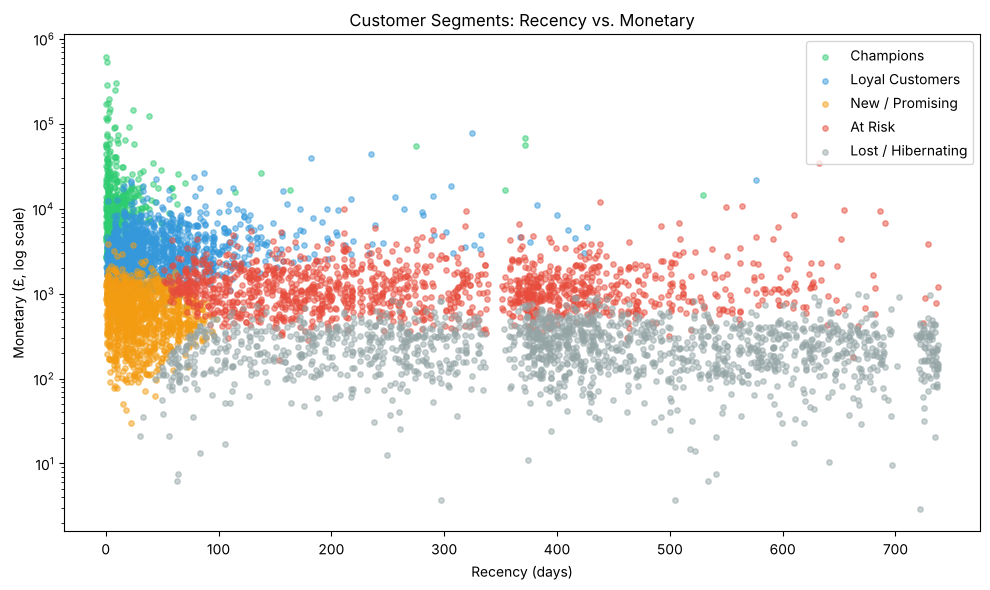

In [48]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 6))

colors = {
    "Champions": "#2ecc71",
    "Loyal Customers": "#3498db",
    "New / Promising": "#f39c12",
    "At Risk": "#e74c3c",
    "Lost / Hibernating": "#95a5a6",
}

for segment, color in colors.items():
    subset = rfm[rfm["Segment"] == segment]
    ax.scatter(
        subset["Recency"],
        subset["Monetary"],
        label=segment,
        color=color,
        alpha=0.5,
        s=15,
    )

ax.set_yscale("log")
ax.set_xlabel("Recency (days)")
ax.set_ylabel("Monetary (£, log scale)")
ax.set_title("Customer Segments: Recency vs. Monetary")
ax.legend()
plt.tight_layout()
plt.savefig("segment_scatter.png", dpi=150)
plt.show()


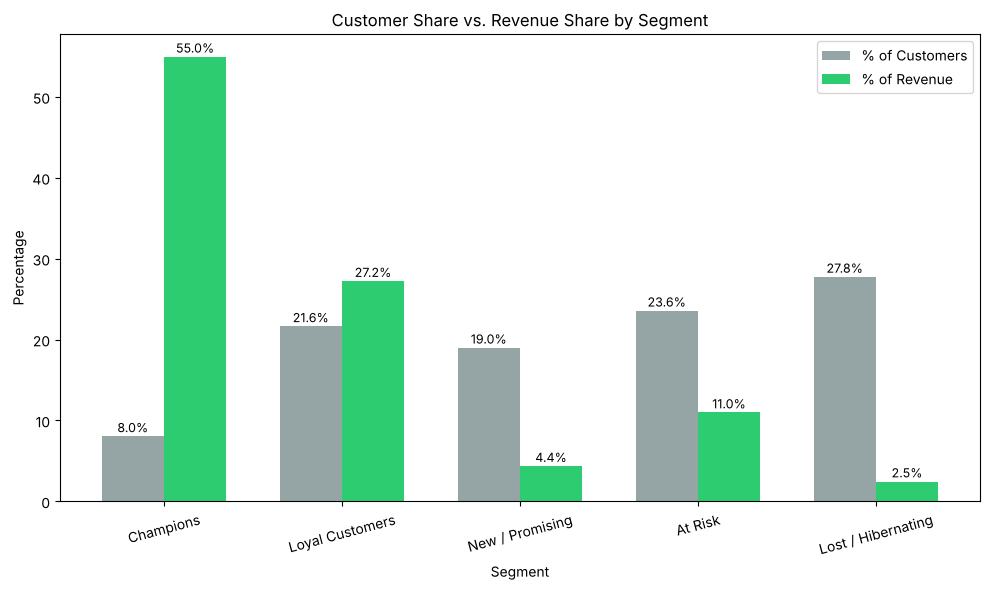

In [49]:
import matplotlib.pyplot as plt
import numpy as np

segment_order_plot = [
    "Champions",
    "Loyal Customers",
    "New / Promising",
    "At Risk",
    "Lost / Hibernating",
]
plot_data = segment_summary.set_index("Segment").loc[segment_order_plot]

fig, ax = plt.subplots(figsize=(10, 6))

x = np.arange(len(segment_order_plot))
width = 0.35

bars1 = ax.bar(
    x - width / 2,
    plot_data["Pct_of_Customers"],
    width,
    label="% of Customers",
    color="#95a5a6",
)
bars2 = ax.bar(
    x + width / 2,
    plot_data["Pct_of_Revenue"],
    width,
    label="% of Revenue",
    color="#2ecc71",
)

ax.set_xlabel("Segment")
ax.set_ylabel("Percentage")
ax.set_title("Customer Share vs. Revenue Share by Segment")
ax.set_xticks(x)
ax.set_xticklabels(segment_order_plot, rotation=15)
ax.legend()

for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()
        ax.annotate(
            f"{height:.1f}%",
            xy=(bar.get_x() + bar.get_width() / 2, height),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center",
            fontsize=9,
        )

plt.tight_layout()
plt.savefig("segment_revenue_share.png", dpi=150)
plt.show()


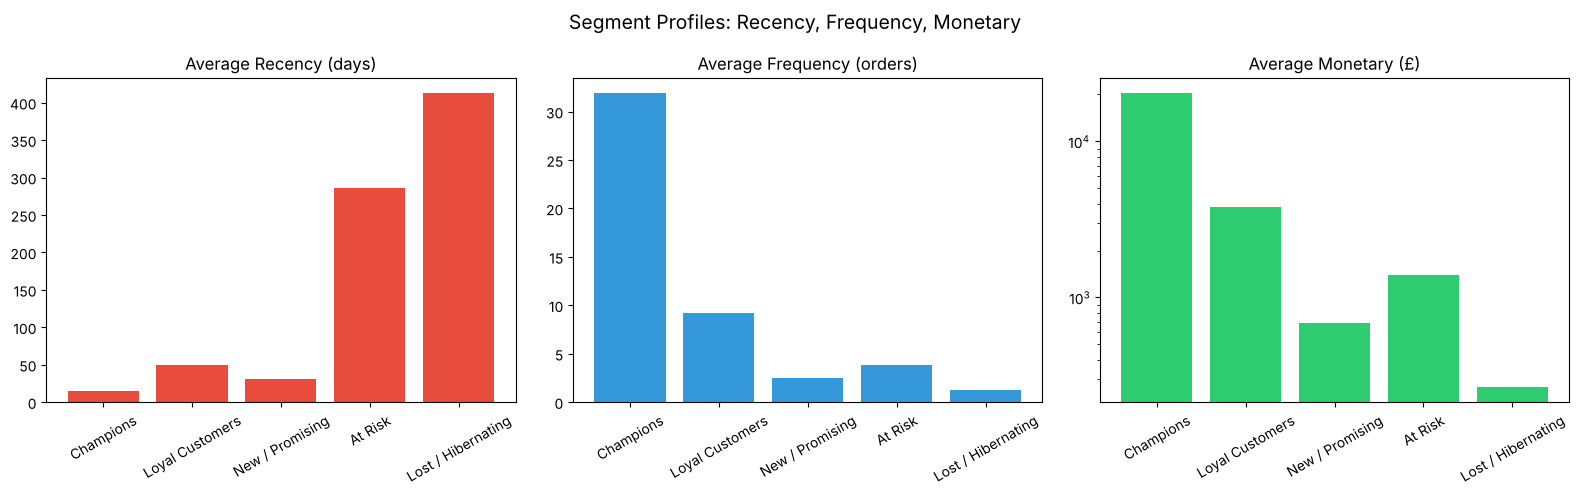

In [50]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

metrics = ["Avg_Recency", "Avg_Frequency", "Avg_Monetary"]
titles = [
    "Average Recency (days)",
    "Average Frequency (orders)",
    "Average Monetary (£)",
]
colors_list = ["#e74c3c", "#3498db", "#2ecc71"]

for ax, metric, title, color in zip(axes, metrics, titles, colors_list):
    ax.bar(plot_data.index, plot_data[metric], color=color)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
    if metric == "Avg_Monetary":
        ax.set_yscale("log")

plt.suptitle("Segment Profiles: Recency, Frequency, Monetary", fontsize=14)
plt.tight_layout()
plt.savefig("segment_profiles.png", dpi=150)
plt.show()


---

# Part 5: Revenue Forecasting

A separate question from the segmentation: how well can daily revenue be forecast?

**How to read the forecast numbers:**

- **MAE:** the average size of the miss, in pounds per day.

- **RMSE:** like MAE, but big misses count for more.

- **MAPE:** the average miss as a percentage of the real value. Lower is better.

## Load the Cleaned Data

In [51]:
import pandas as pd

data = pd.read_csv("cleaned_retail.csv")
data["InvoiceDate"] = pd.to_datetime(data["InvoiceDate"])

print(data.shape)


(804824, 8)


## Daily Revenue

Calculate revenue, then add it up per day in the format Prophet expects.

In [52]:
data["Revenue"] = data["Quantity"] * data["Price"]

daily_revenue = data.groupby(data["InvoiceDate"].dt.date)["Revenue"].sum().reset_index()
daily_revenue.columns = ["ds", "y"]

print(daily_revenue.shape)
print(daily_revenue.head())


(604, 2)
           ds         y
0  2009-12-01  44048.69
1  2009-12-02  52941.99
2  2009-12-03  67479.08
3  2009-12-04  34063.35
4  2009-12-05   9803.05


Plot the autocorrelation (ACF) and partial autocorrelation (PACF) of daily revenue.

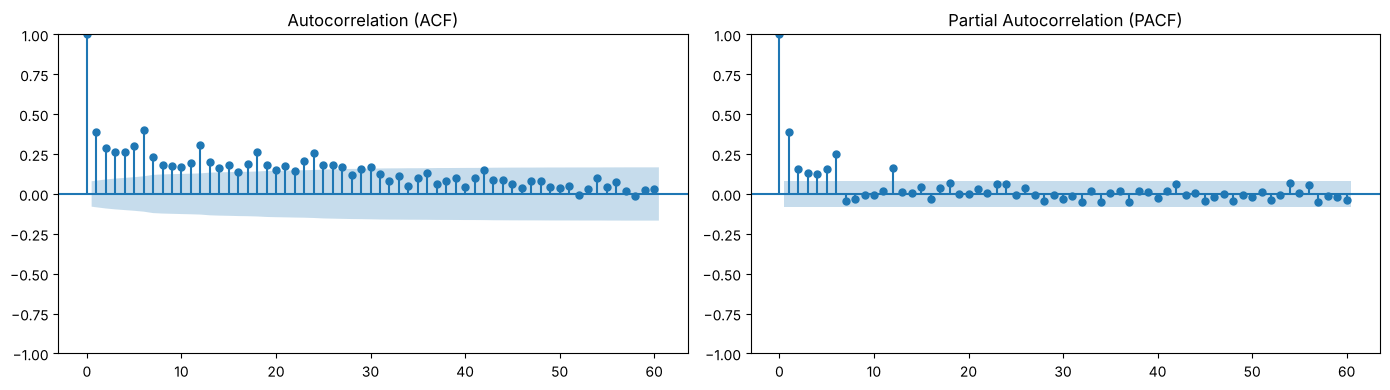

In [53]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
plot_acf(daily_revenue["y"], lags=60, ax=axes[0])
plot_pacf(daily_revenue["y"], lags=60, ax=axes[1])
axes[0].set_title("Autocorrelation (ACF)")
axes[1].set_title("Partial Autocorrelation (PACF)")
plt.tight_layout()
plt.show()


## Autocorrelation Check (ACF/PACF)

Before building any forecasting model, checked whether daily revenue is actually related to its own past values — the core assumption forecasting depends on.

**ACF**: shows a slow overall decay rather than dropping quickly to zero, with small recurring bumps roughly every 6-7 lags. The slow decay suggests a trend component is still present in the raw daily revenue series.

**PACF**: shows a clear significant spike at lag 1 (~0.39) and a second significant spike around lag 6-7 (~0.25), with most other lags falling inside the "not significant" band.

**Interpretation**: the lag-1 spike indicates some day-to-day momentum in revenue (today's revenue is somewhat related to yesterday's). The lag-6/7 spike indicates a real **weekly seasonality pattern** — some days of the week are reliably higher or lower than others, consistent with typical retail shopping behavior (e.g., weekday vs. weekend patterns).

**Why this matters:** this gives statistical justification (not just visual impression) for using weekly seasonality settings in Prophet, and for setting SARIMA's seasonal period parameter to 7. The slow ACF decay is also informal evidence the series is likely non-stationary — tested formally in the next step.

In [54]:
from statsmodels.tsa.stattools import adfuller

result = adfuller(daily_revenue["y"])

print(f"ADF Statistic: {result[0]:.4f}")
print(f"p-value: {result[1]:.4f}")
print("Critical Values:")
for key, value in result[4].items():
    print(f"   {key}: {value:.4f}")


ADF Statistic: -2.3005
p-value: 0.1718
Critical Values:
   1%: -3.4414
   5%: -2.8664
   10%: -2.5694


## Stationarity Check (Augmented Dickey-Fuller Test)

Ran a formal ADF test on daily revenue to confirm the non-stationarity suggested by the slow-decaying ACF pattern.

**Result:** ADF Statistic = -2.3005, p-value = 0.1718. Since the p-value exceeds 0.05 and the ADF statistic does not cross any critical value threshold (1%, 5%, or 10%), the null hypothesis of non-stationarity cannot be rejected — the series is non-stationary.

**Why this matters:** Prophet handles trend internally, so it needs no adjustment. The tree-based models (XGBoost, Random Forest) have no formal stationarity requirement, and the lag and rolling-average features built for them help capture the same trend.

## Train/Test Split

In [55]:
train_size = int(len(daily_revenue) * 0.85)
train = daily_revenue.iloc[:train_size]
test = daily_revenue.iloc[train_size:]

print("Train:", train.shape, train["ds"].min(), "to", train["ds"].max())
print("Test:", test.shape, test["ds"].min(), "to", test["ds"].max())


Train: (513, 2) 2009-12-01 to 2011-08-24
Test: (91, 2) 2011-08-25 to 2011-12-09


## Prophet

Fit Prophet on the training data.

In [56]:
from prophet import Prophet

model = Prophet(
    yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False
)

model.fit(train)


In [57]:
# Predict every date in the test period.
# The test days are trading days, so asking for the next 91 calendar days would stop too early.
test = test.copy()
test["ds"] = pd.to_datetime(test["ds"])

forecast = model.predict(test[["ds"]])

print(forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail(10))

           ds          yhat    yhat_lower    yhat_upper
81 2011-11-29  59801.102550  46327.635829  74303.452418
82 2011-11-30  57042.608372  42948.661684  70247.821085
83 2011-12-01  64102.608179  50876.843657  77436.016985
84 2011-12-02  52631.429417  39099.568023  65421.766716
85 2011-12-04  45208.518873  30962.289218  58903.556125
86 2011-12-05  54053.713237  40524.580659  67383.800853
87 2011-12-06  56207.056129  42759.128471  69379.904667
88 2011-12-07  51857.104322  37946.415310  64848.569918
89 2011-12-08  57308.679183  44962.052595  71087.378751
90 2011-12-09  44241.851705  30417.238954  56912.305274


In [58]:
comparison = test.merge(
    forecast[["ds", "yhat", "yhat_lower", "yhat_upper"]], on="ds"
)
comparison.columns = ["ds", "actual", "predicted", "lower", "upper"]

print("Test days:", len(test))
print("Days scored:", len(comparison))
print(comparison.head(10))

Test days: 91
Days scored: 91
          ds    actual     predicted         lower         upper
0 2011-08-25  22495.29  32511.075106  18530.872407  45641.476151
1 2011-08-26  24111.64  20830.038201   8135.081327  33887.479429
2 2011-08-28  10805.03  13640.122664     44.746864  26479.744069
3 2011-08-30   8833.71  25871.787764  12603.857874  39074.366005
4 2011-08-31  20540.84  22547.643769   8642.931984  35758.736320
5 2011-09-01  36882.36  29306.810359  17058.523717  42709.073194
6 2011-09-02  29444.25  17829.537820   5404.404400  30784.474654
7 2011-09-04  17005.03  11374.495818  -1989.500982  24789.425403
8 2011-09-05  35694.70  21227.308368   7886.181903  34415.864001
9 2011-09-06  25480.82  24749.055551  11366.304986  37601.334875


In [59]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

mae = mean_absolute_error(comparison["actual"], comparison["predicted"])
rmse = np.sqrt(mean_squared_error(comparison["actual"], comparison["predicted"]))
mape = (
    np.mean(
        np.abs((comparison["actual"] - comparison["predicted"]) / comparison["actual"])
    )
    * 100
)

print(f"MAE: {mae:.2f}")
print(f"RMSE: {rmse:.2f}")
print(f"MAPE: {mape:.2f}%")


MAE: 12219.15
RMSE: 20559.70
MAPE: 34.12%


## Prophet Model: Results

Trained on 513 days (Dec 2009 to Aug 2011), tested on all 91 held-out days (Aug to Dec 2011). Weekly and yearly seasonality are enabled, based on the autocorrelation check above. Prophet warns that yearly seasonality is less stable with under 2 years of training history (513 days is about 1.7 years).

**Results:**
- MAE: £12,219
- RMSE: £20,560
- MAPE: 34.1%

**Interpretation:** the error is fairly high for a day-level forecast. RMSE is well above MAE, which means a few large individual misses rather than consistent small errors. Daily revenue is naturally volatile: single large orders (as seen with the wholesale-scale customers in the segmentation) cause big one-day swings that are hard to predict.

<br>

## Prophet on Log Revenue

Daily revenue is right-skewed: most days are moderate and a few are very large. Training on the **log** of revenue stops those few large days from dominating the model. The predictions are converted back to pounds before scoring.

<br>

In [60]:
train_log = train.copy()
train_log["y"] = np.log1p(train_log["y"])

model_log = Prophet(
    yearly_seasonality=True, weekly_seasonality=True, daily_seasonality=False
)
model_log.fit(train_log)

forecast_log = model_log.predict(test[["ds"]])

# Convert the predictions back from log to pounds
prophet_log_pred = np.expm1(forecast_log["yhat"].values)

log_mae = mean_absolute_error(test["y"], prophet_log_pred)
log_rmse = np.sqrt(mean_squared_error(test["y"], prophet_log_pred))
log_mape = np.mean(np.abs((test["y"].values - prophet_log_pred) / test["y"].values)) * 100

print(f"MAE: {log_mae:.2f}")
print(f"RMSE: {log_rmse:.2f}")
print(f"MAPE: {log_mape:.2f}%")

MAE: 12160.84
RMSE: 21017.43
MAPE: 31.01%


<br>

**Result:** training on log revenue lowers Prophet's error from 34.1% to 31.0% on the same 91 test days.

<br>

## Tree Models: Lag and Rolling-Average Features

XGBoost and Random Forest cannot read a date directly, so they are given recent history as features: revenue 1, 7 and 14 days ago, and rolling averages.

In [61]:
df = daily_revenue.copy()
df["ds"] = pd.to_datetime(df["ds"])
df = df.sort_values("ds").reset_index(drop=True)

# Lag features: revenue from 1, 7, and 14 days ago
df["lag_1"] = df["y"].shift(1)
df["lag_7"] = df["y"].shift(7)
df["lag_14"] = df["y"].shift(14)

# Rolling average features: average revenue over the past 7 and 14 days
df["rolling_mean_7"] = df["y"].shift(1).rolling(window=7).mean()
df["rolling_mean_14"] = df["y"].shift(1).rolling(window=14).mean()

# Day-of-week as a feature, since we confirmed a real weekly pattern
df["day_of_week"] = df["ds"].dt.dayofweek

print(df.shape)
print(df.head(20))


(604, 8)
           ds         y     lag_1     lag_7    lag_14  rolling_mean_7  \
0  2009-12-01  44048.69       NaN       NaN       NaN             NaN   
1  2009-12-02  52941.99  44048.69       NaN       NaN             NaN   
2  2009-12-03  67479.08  52941.99       NaN       NaN             NaN   
3  2009-12-04  34063.35  67479.08       NaN       NaN             NaN   
4  2009-12-05   9803.05  34063.35       NaN       NaN             NaN   
5  2009-12-06  24580.72   9803.05       NaN       NaN             NaN   
6  2009-12-07  33169.63  24580.72       NaN       NaN             NaN   
7  2009-12-08  44744.69  33169.63  44048.69       NaN    38012.358571   
8  2009-12-09  31113.60  44744.69  52941.99       NaN    38111.787143   
9  2009-12-10  37593.34  31113.60  67479.08       NaN    34993.445714   
10 2009-12-11  39415.88  37593.34  34063.35       NaN    30724.054286   
11 2009-12-13  21711.46  39415.88   9803.05       NaN    31488.701429   
12 2009-12-14  51308.43  21711.46  24580.7

In [62]:
df_clean = df.dropna().reset_index(drop=True)
print(df_clean.shape)
print(df_clean.head())


(590, 8)
          ds         y     lag_1     lag_7    lag_14  rolling_mean_7  \
0 2009-12-16  37174.00  46914.58  44744.69  44048.69    38971.711429   
1 2009-12-17  29541.24  37174.00  31113.60  52941.99    37890.184286   
2 2009-12-18  31658.02  29541.24  37593.34  67479.08    37665.561429   
3 2009-12-20  11423.33  31658.02  39415.88  34063.35    36817.658571   
4 2009-12-21  15424.98  11423.33  21711.46   9803.05    32818.722857   

   rolling_mean_14  day_of_week  
0     38492.035000            2  
1     38000.985714            3  
2     36329.503571            4  
3     33770.856429            6  
4     32153.712143            0  


In [63]:
train_size_ml = int(len(df_clean) * 0.85)
train_ml = df_clean.iloc[:train_size_ml]
test_ml = df_clean.iloc[train_size_ml:]

print("Train:", train_ml.shape, train_ml["ds"].min(), "to", train_ml["ds"].max())
print("Test:", test_ml.shape, test_ml["ds"].min(), "to", test_ml["ds"].max())


Train: (501, 8) 2009-12-16 00:00:00 to 2011-08-26 00:00:00
Test: (89, 8) 2011-08-28 00:00:00 to 2011-12-09 00:00:00


Separate the features (X) from the target (y), then fit XGBoost.

In [64]:
feature_cols = [
    "lag_1",
    "lag_7",
    "lag_14",
    "rolling_mean_7",
    "rolling_mean_14",
    "day_of_week",
]

X_train = train_ml[feature_cols]
y_train = train_ml["y"]
X_test = test_ml[feature_cols]
y_test = test_ml["y"]

from xgboost import XGBRegressor

xgb_model = XGBRegressor(
    n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42
)
xgb_model.fit(X_train, y_train)

xgb_predictions = xgb_model.predict(X_test)

print(xgb_predictions[:10])


[15436.277 23744.95  21000.676 30391.062 20093.785 15670.631 21295.094
 30886.902 26172.924 32778.688]


In [65]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_rmse = np.sqrt(mean_squared_error(y_test, xgb_predictions))
xgb_mape = np.mean(np.abs((y_test - xgb_predictions) / y_test)) * 100

print(f"XGBoost MAE: {xgb_mae:.2f}")
print(f"XGBoost RMSE: {xgb_rmse:.2f}")
print(f"XGBoost MAPE: {xgb_mape:.2f}%")


XGBoost MAE: 13067.62
XGBoost RMSE: 21739.60
XGBoost MAPE: 33.86%


In [66]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_predictions)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_predictions))
rf_mape = np.mean(np.abs((y_test - rf_predictions) / y_test)) * 100

print(f"Random Forest MAE: {rf_mae:.2f}")
print(f"Random Forest RMSE: {rf_rmse:.2f}")
print(f"Random Forest MAPE: {rf_mape:.2f}%")


Random Forest MAE: 12724.79
Random Forest RMSE: 21150.89
Random Forest MAPE: 34.49%


<br>

Train the same two tree models on log revenue as well, so every model gets the same treatment.

<br>

In [67]:
xgb_log = XGBRegressor(
    n_estimators=100, max_depth=4, learning_rate=0.1, random_state=42
)
xgb_log.fit(X_train, np.log1p(y_train))
xgb_log_predictions = np.expm1(xgb_log.predict(X_test))

rf_log = RandomForestRegressor(n_estimators=100, max_depth=4, random_state=42)
rf_log.fit(X_train, np.log1p(y_train))
rf_log_predictions = np.expm1(rf_log.predict(X_test))

xgb_log_mape = np.mean(np.abs((y_test - xgb_log_predictions) / y_test)) * 100
rf_log_mape = np.mean(np.abs((y_test - rf_log_predictions) / y_test)) * 100

print(f"XGBoost on log revenue MAPE: {xgb_log_mape:.2f}%")
print(f"Random Forest on log revenue MAPE: {rf_log_mape:.2f}%")

XGBoost on log revenue MAPE: 32.76%
Random Forest on log revenue MAPE: 30.97%


<br>

## Model Comparison on the Same Test Days

The tree models lose their first 14 days to the lag features, so their test period is 89 days. To compare fairly, every model is scored on those same 89 days.

A **simple guess** is included as a baseline: always predict the average daily revenue of the training period. A model is only useful if it beats that.

<br>

In [68]:
same_days = pd.DataFrame({"ds": test_ml["ds"].values})
actual = test_ml["y"].values

prophet_same = model.predict(same_days)["yhat"].values
prophet_log_same = np.expm1(model_log.predict(same_days)["yhat"].values)
simple_guess = np.full(len(actual), train["y"].mean())

results = {
    "Prophet": prophet_same,
    "Prophet on log revenue": prophet_log_same,
    "XGBoost": xgb_predictions,
    "XGBoost on log revenue": xgb_log_predictions,
    "Random Forest": rf_predictions,
    "Random Forest on log revenue": rf_log_predictions,
    "Simple guess: training average": simple_guess,
}

rows = []
for name, predicted in results.items():
    rows.append(
        {
            "Model": name,
            "MAE (£)": mean_absolute_error(actual, predicted),
            "MAPE (%)": np.mean(np.abs((actual - predicted) / actual)) * 100,
        }
    )

model_comparison = pd.DataFrame(rows).sort_values("MAPE (%)").reset_index(drop=True)

print("Test days used for every model:", len(actual))
model_comparison.round(1)

Test days used for every model: 89


,Model,MAE (£),MAPE (%)
0,Random Forest on log revenue,12547.7,31.0
1,Prophet on log revenue,12311.8,31.2
2,XGBoost on log revenue,12874.4,32.8
3,XGBoost,13067.6,33.9
4,Prophet,12344.3,34.2
5,Random Forest,12724.8,34.5
6,Simple guess: training average,17741.5,40.9


## Model Comparison: Final Results

Every model scored on the same 89 test days.

| Model | MAE | MAPE |
|---|---|---|
| Random Forest on log revenue | £12,548 | 31.0% |
| **Prophet on log revenue (chosen)** | **£12,312** | **31.2%** |
| XGBoost on log revenue | £12,874 | 32.8% |
| XGBoost | £13,068 | 33.9% |
| Prophet | £12,344 | 34.2% |
| Random Forest | £12,725 | 34.5% |
| Simple guess: training average | £17,741 | 40.9% |

**What this shows:**

- **Every model beats the simple guess.** The simple guess is off by about 41% on a typical day; the models are off by 31% to 35%.

- **The three model types are close.** On raw revenue they are within a point of each other (33.9% to 34.5%), so no model type is a clear winner.

- **Training on log revenue helps every model**, by about 2 to 3 points.

**Chosen model: Prophet on log revenue.** It has the lowest average miss in pounds (£12,312) and a MAPE within 0.2 points of the best. It also forecasts the whole test period in one go. The tree models need the previous day's actual revenue for every prediction, which is an easier task than forecasting months ahead.

**Scope note:** an LSTM model was also planned, but was dropped after a NumPy/TensorFlow version conflict repeatedly crashed the training environment. With only about 590 days of data, a deep learning model was unlikely to help.

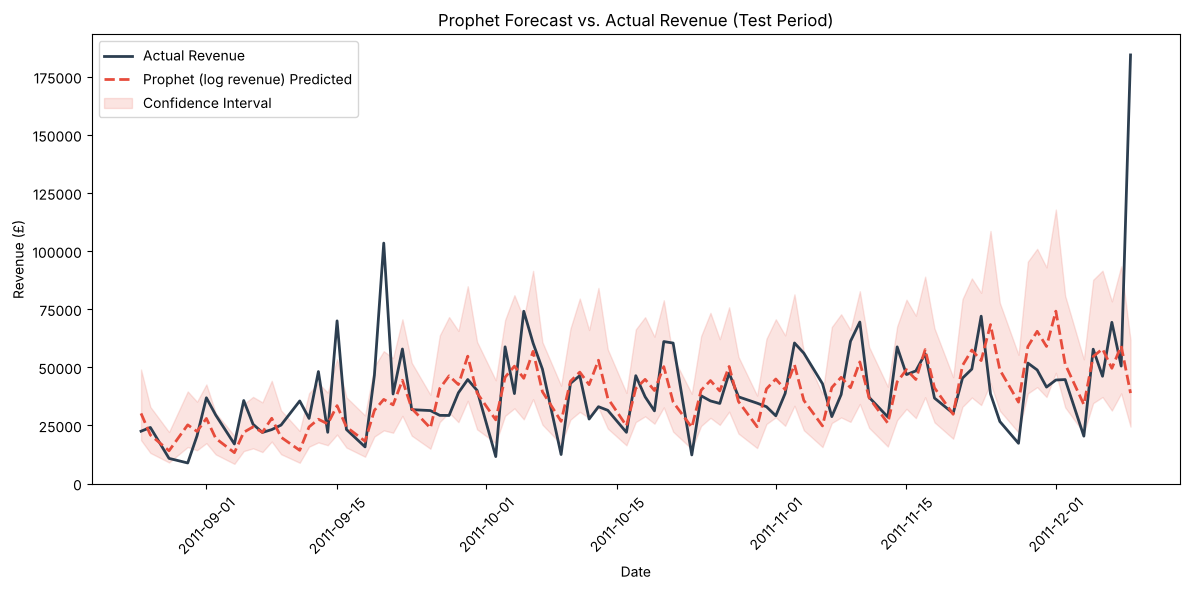

In [69]:
import matplotlib.pyplot as plt

# Chart the chosen model: Prophet on log revenue, converted back to pounds
final = pd.DataFrame(
    {
        "ds": test["ds"].values,
        "actual": test["y"].values,
        "predicted": prophet_log_pred,
        "lower": np.expm1(forecast_log["yhat_lower"].values),
        "upper": np.expm1(forecast_log["yhat_upper"].values),
    }
)

fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(final["ds"], final["actual"], label="Actual Revenue", color="#2c3e50", linewidth=2)
ax.plot(
    final["ds"],
    final["predicted"],
    label="Prophet (log revenue) Predicted",
    color="#e74c3c",
    linewidth=2,
    linestyle="--",
)
ax.fill_between(
    final["ds"],
    final["lower"],
    final["upper"],
    color="#e74c3c",
    alpha=0.15,
    label="Confidence Interval",
)

ax.set_xlabel("Date")
ax.set_ylabel("Revenue (£)")
ax.set_title("Prophet Forecast vs. Actual Revenue (Test Period)")
ax.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("forecast_vs_actual.png", dpi=150)
plt.show()

## Forecast Visualization: Actual vs. Predicted

The forecast follows the general level and the weekly rhythm of revenue reasonably well. The sharpest spikes fall outside the shaded interval: one-off days driven by a single very large order, consistent with the wholesale accounts found in the segmentation.

This suggests day-level revenue forecasting is limited by the unpredictability of individual large orders. A business using this forecast should treat single-day predictions with caution. Weekly or monthly totals, which smooth out one-off spikes, are likely to be more reliable.